# 00 — Binary floating-point spacing and ULP staircase

**Goal.** Reproduce the basic mechanism behind the research report: the spacing of adjacent IEEE 754 values grows by powers of two. All experiments use `n=10`, and evaluate the *same stored* `y = fl(x**10)` twice in `fl(fl(y+c)-y)`.

**Sources.** `ulp.ipynb`, *relatorio_ulp.pdf* (Section 2), *artigo_ulp.pdf* (Sections 1–3), and Figures 01–03 of the English LaTeX report.

**Expected observation.** The binary64 ULP of `x**10` passes through 1 at `x=2**(52/10)` and becomes 2 at `x=2**(53/10) ≈ 39.3966`.

In [1]:
from pathlib import Path
import sys, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.patches import Patch
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'ulp_lab.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'ulp_lab.py').exists():
    raise FileNotFoundError('Open Jupyter in the extracted ULP_Jupyter_Reproducibility folder.')
sys.path.insert(0, str(ROOT / 'src'))
from ulp_lab import (evaluate, ulp, v2, floor_log2, theory, possible_results,
                     sample_binade, valid_same_binade_mask, generate_cases, validate_one)
FIG = ROOT / 'figures'; FIG.mkdir(exist_ok=True)
RES = ROOT / 'results'; RES.mkdir(exist_ok=True)
BLUE='#2367A6'; ORANGE='#DD8A29'; GREEN='#2C977F'; RED='#B85751'; PURPLE='#8572AB'
plt.rcParams.update({'font.size':10,'figure.dpi':110,'savefig.dpi':190,
                     'axes.grid':True,'grid.alpha':.20,
                     'axes.spines.top':False,'axes.spines.right':False})
print('Working directory:', ROOT)
print('NumPy:', np.__version__)

Working directory: /mnt/data/ULP_Jupyter_Reproducibility
NumPy: 2.3.5


## Definition and rounding assumptions

For a normal positive binary floating-point number `y` in binade $[2^E,2^{E+1})$,

$$\mathrm{ULP}(y)=2^{E-p+1},\qquad p=53\;(\mathrm{binary64}),\quad p=24\;(\mathrm{binary32}).$$

We use round-to-nearest, ties-to-even (the normal NumPy/IEEE 754 mode) and finite positive inputs. This calculation measures an *arithmetic rounding effect*, not necessarily classical catastrophic cancellation in the final subtraction. In the modeled regime the final subtraction is exact (Sterbenz's lemma).

In [2]:
for dtype in (np.float64, np.float32):
    p = 53 if dtype is np.float64 else 24
    threshold = 2 ** (p / 10)
    r, y = evaluate(dtype(40) if dtype is np.float64 else dtype(6), 1, dtype)
    print(f'{dtype.__name__:>7} | p={p} | 1st odd-integer threshold = {threshold:.9f}')
    print('             example y=',y,' ULP(y)=',ulp(y,dtype),' f(x,1)=',r)

assert abs(theory(1).x1 - 39.396621227037315) < 1e-12
assert theory(1,np.float32).p == 24

float64 | p=53 | 1st odd-integer threshold = 39.396621227
             example y= 1.048576e+16  ULP(y)= 2.0  f(x,1)= 0.0
float32 | p=24 | 1st odd-integer threshold = 5.278031643
             example y= 6.0466176e+07  ULP(y)= 4.0  f(x,1)= 0.0


## Figure 01 — the staircase of $\log_2\mathrm{ULP}(x^{10})$

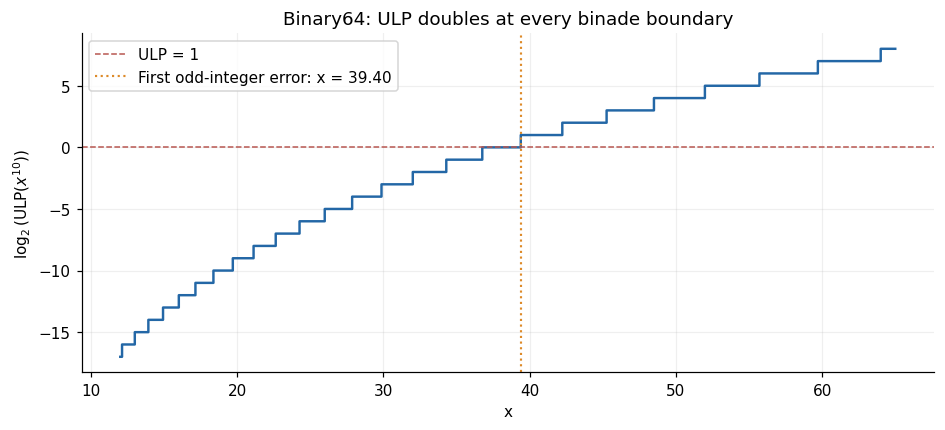

In [3]:
x = np.linspace(12,65,2800,dtype=np.float64)
_, y = evaluate(x,1,np.float64)
u = ulp(y,np.float64)
fig,ax=plt.subplots(figsize=(10,4))
ax.step(x,np.log2(u),where='mid',color=BLUE,lw=1.6)
ax.axhline(0,color=RED,ls='--',lw=1,label='ULP = 1')
ax.axvline(theory(1).x1,color=ORANGE,ls=':',lw=1.4,
           label=f'First odd-integer error: x = {theory(1).x1:.2f}')
ax.set(xlabel='x',ylabel=r'$\log_2(\mathrm{ULP}(x^{10}))$',
       title='Binary64: ULP doubles at every binade boundary')
ax.legend(loc='upper left')
fig.savefig(FIG / '01_ulp_staircase.png', bbox_inches='tight', facecolor='white'); plt.show(); plt.close(fig)

## Numerical binade table

The boundaries below come from $x=2^{E/10}$. This is an idealized location based on the exponent of the *computed* `y`; exact `x` transition points can differ by one or a few input floating-point values.

In [4]:
rows=[]
for E in range(46,60):
    rows.append({'E':E,'x start':2**(E/10),'x end':2**((E+1)/10),
                 'ULP binary64':math.ldexp(1.0,E-52)})
df=pd.DataFrame(rows)
display(df.round({'x start':4,'x end':4}))
df.to_csv(RES/'00_ulp_binade_table.csv',index=False)
assert np.all(np.diff(np.log2(df['ULP binary64'].to_numpy())) == 1)

,E,x start,x end,ULP binary64
0,46,24.2515,25.9921,0.015625
1,47,25.9921,27.8576,0.031250
2,48,27.8576,29.8571,0.062500
3,49,29.8571,32.0000,0.125000
4,50,32.0000,34.2968,0.250000
5,51,34.2968,36.7583,0.500000
6,52,36.7583,39.3966,1.000000
7,53,39.3966,42.2243,2.000000
8,54,42.2243,45.2548,4.000000
9,55,45.2548,48.5029,8.000000


## Conclusion

The growth is **discrete**, not smooth. Increasing `x` by a factor $2^{1/10}\approx1.07177$ doubles the ULP of `x**10`. An added increment smaller than half that spacing can disappear entirely. The next notebook measures this transition over 780 combinations.